# Scalability: accuracy and runtime


Compares accuracy and runtime across graph sizes. Failed fits remain visible through the coverage policy.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("scalability")
sources = th.load_aligned_sources()
benchmark_data = sources["benchmark_data"]
benchmark_with_biological = sources["benchmark_with_biological"]


In [2]:
legacy_scalability = th.prepare_metrics(th.load_historical_benchmark())
legacy_scalability = legacy_scalability.loc[legacy_scalability.n_nodes.ne(20)]
scalability_base = pd.concat(
    [legacy_scalability, benchmark_with_biological], ignore_index=True, sort=False
)
scalability = fv.load_scalability_data(
    th.visualization_data(scalability_base), project_root=ROOT
)


## Runtime


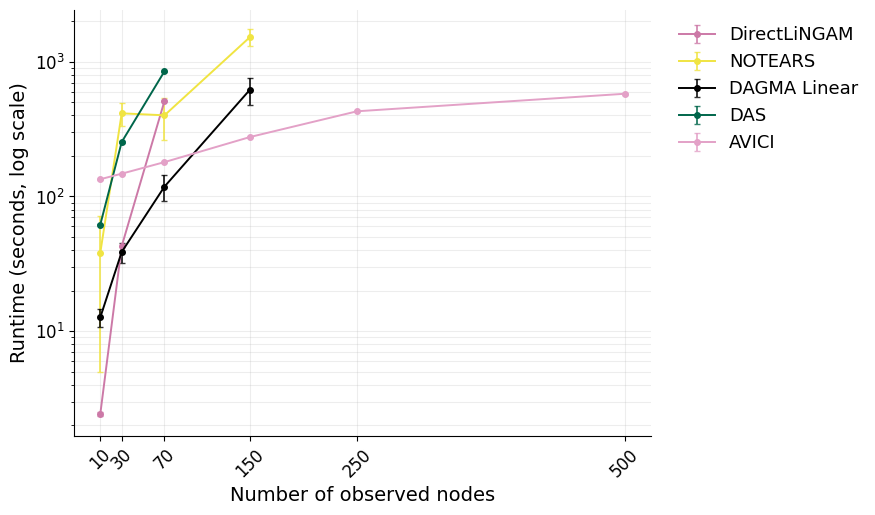

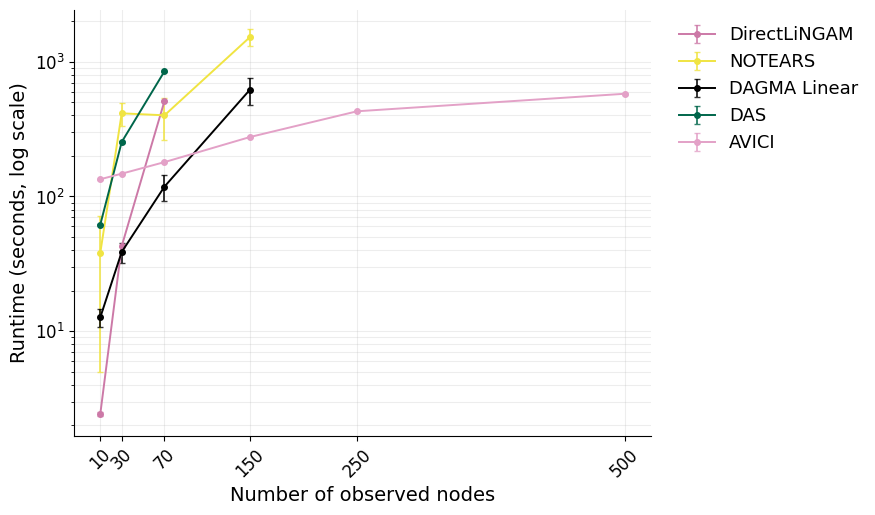

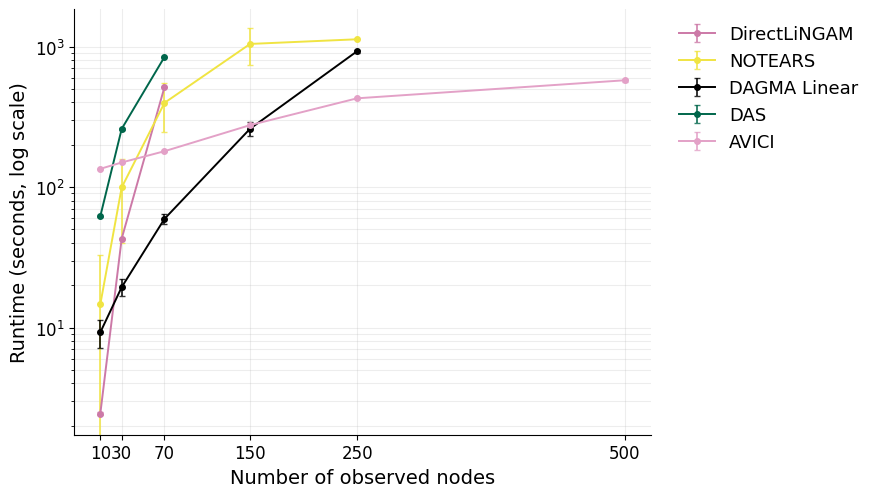

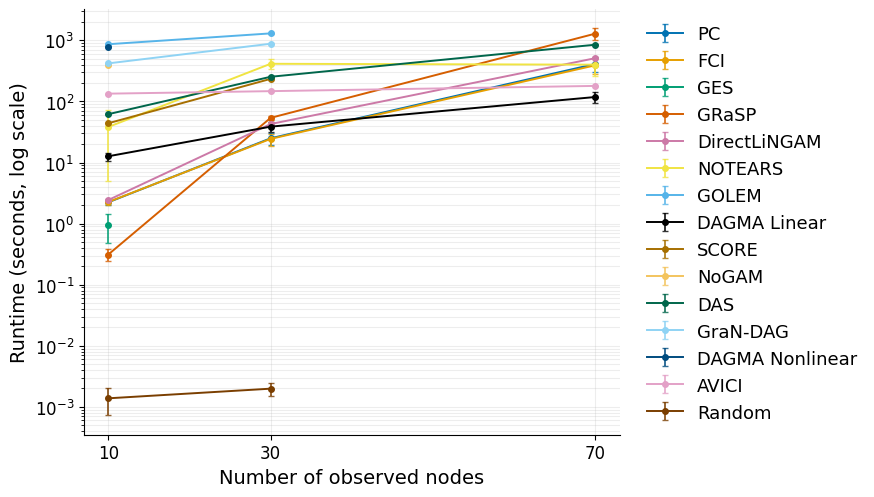

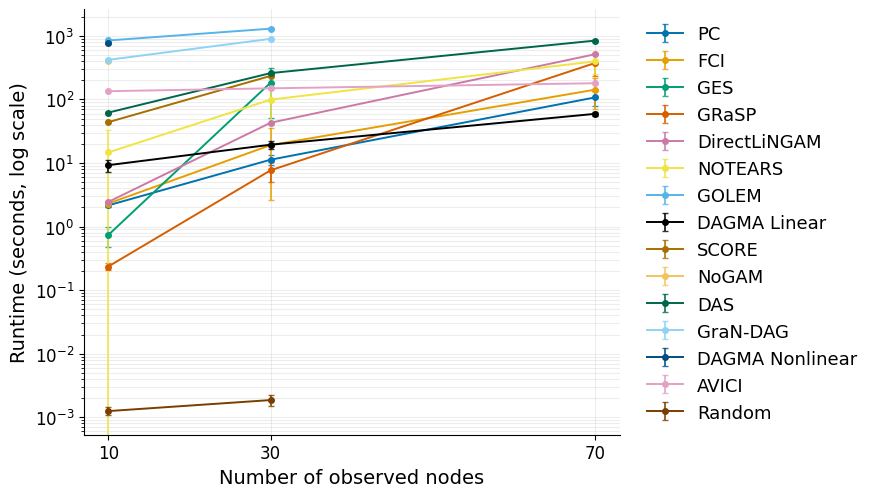

In [3]:
_, _, runtime_output = fv.plot_scalability_runtime(
    benchmark_data,
    scalability_data=scalability,
    exclude_n_nodes=(15, 20, 100),
    top_n_models=5,
    uncertainty="sd",
    separate_families=True,
    show_metric_title=False,
    show_family_titles=False,
    zoom_max_nodes=70,
    show_coverage=False,
    errorbar_alpha=0.8,
    font_size=14,
    figsize=(9, 5.2),
)
runtime_fig = runtime_output["figures"]["eb_gaussian_linear"]
runtime_output["axes_by_family"]["eb_gaussian_linear"].tick_params(axis="x", labelrotation=45)
runtime_pdf = th.save_pdf(runtime_fig, "runtime_gaussian_linear.pdf")
display(runtime_fig)
for figure in runtime_output["figures"].values():
    display(figure)
    plt.close(figure)
for figure in runtime_output.get("zoom_figures", {}).values():
    display(figure)
    plt.close(figure)
for figure in runtime_output.get("coverage_figures", {}).values():
    display(figure)
    plt.close(figure)


## Accuracy tables


In [4]:
scalability_finished = scalability.loc[scalability.status.eq("finished")].copy()
scale_cells = (
    scalability_finished.groupby(
        ["scalability_family", "n_nodes", "dataset_seed", "model"], observed=True
    )["f1"]
    .mean()
    .reset_index()
)
scale_summary = (
    scale_cells.groupby(["scalability_family", "n_nodes", "model"], observed=True)["f1"]
    .agg(["mean", "std", "size"])
    .reset_index()
)
scale_summary["F1"] = scale_summary.apply(
    lambda row: f"{row['mean']:.3f} ± {row['std']:.3f}", axis=1
)
display(scale_summary)
scale_gaussian = scale_summary.loc[scale_summary.scalability_family.eq("eb_gaussian_linear")]
scale_wide = scale_gaussian.pivot(index="model", columns="n_nodes", values="mean")
scale_wide = scale_wide.reindex(
    index=[
        "PC",
        "FCI",
        "GES",
        "GRaSP",
        "DirectLiNGAM",
        "NOTEARS",
        "GOLEM",
        "DAGMA_Linear",
        "SCORE",
        "NoGAM",
        "DAS",
        "GraNDAG",
        "DAGMA_Nonlinear",
        "AVICI",
        "Random",
    ],
    columns=[10, 15, 20, 30, 70, 100, 150, 250, 500],
)
scale_wide = scale_wide.map(lambda value: "--" if pd.isna(value) else f"{value:.2f}")
scale_wide.index = [th.model_label(model) for model in scale_wide.index]
scale_wide = scale_wide.reset_index(names="Model")


,scalability_family,n_nodes,model,mean,std,size,F1
0,eb_gaussian_linear,10.0,AVICI,0.616645,0.125270,15,0.617 ± 0.125
1,eb_gaussian_linear,10.0,DAGMA_Linear,0.268810,0.169676,15,0.269 ± 0.170
2,eb_gaussian_linear,10.0,DAGMA_Nonlinear,0.410625,0.095681,15,0.411 ± 0.096
3,eb_gaussian_linear,10.0,DAS,0.240082,0.131551,15,0.240 ± 0.132
4,eb_gaussian_linear,10.0,DirectLiNGAM,0.431603,0.148130,15,0.432 ± 0.148
...,...,...,...,...,...,...,...
157,eb_nongaussian_mixed,250.0,AVICI,0.004961,0.002560,5,0.005 ± 0.003
158,eb_nongaussian_mixed,250.0,DAGMA_Linear,0.008212,0.001172,5,0.008 ± 0.001
159,eb_nongaussian_mixed,250.0,FCI,0.002273,0.001142,4,0.002 ± 0.001
160,eb_nongaussian_mixed,250.0,NOTEARS,0.005025,NaN,1,0.005 ± nan


In [5]:
display(scale_wide)


n_nodes,Model,10,15,20,30,70,100,150,250,500
0,PC,0.53,0.24,0.17,0.10,0.01,0.01,--,--,--
1,FCI,0.19,0.21,0.09,0.04,0.00,0.00,--,--,--
2,GES,0.63,0.53,0.39,--,--,--,--,--,--
3,GRaSP,0.72,0.80,0.79,0.66,0.18,0.09,--,--,--
4,DirectLiNGAM,0.43,0.32,0.33,0.28,0.17,0.12,--,--,--
5,NOTEARS,0.31,0.29,0.19,0.13,0.04,0.02,0.02,--,--
6,GOLEM,0.23,0.20,0.13,0.09,--,--,--,--,--
7,DAGMA Linear,0.27,0.27,0.19,0.13,0.05,0.02,0.01,--,--
8,SCORE,0.25,0.16,0.12,0.10,--,--,--,--,--
9,NoGAM,0.25,0.17,0.12,--,--,--,--,--,--


## Non-Gaussian mixed mechanisms


In [6]:
mixed = scale_summary.loc[scale_summary.scalability_family.eq("eb_nongaussian_mixed")]
mixed_wide = mixed.pivot(index="model", columns="n_nodes", values="mean")
mixed_wide = mixed_wide.reindex(index=[m for m in fv.DEFAULT_MODEL_ORDER if m != "Random"],
                                columns=[10, 15, 20, 30, 70, 100, 150, 250, 500])
mixed_wide = mixed_wide.map(lambda v: "—" if pd.isna(v) else f"{v:.3f}")
mixed_wide.index = [th.model_label(m) for m in mixed_wide.index]
mixed_wide = mixed_wide.reset_index(names="Method")
display(mixed_wide)


n_nodes,Method,10,15,20,30,70,100,150,250,500
0,PC,0.399,0.291,0.229,0.130,0.045,0.028,0.015,—,—
1,FCI,0.162,0.184,0.165,0.087,0.025,0.015,0.008,0.002,—
2,GES,0.600,0.524,0.537,0.437,—,—,—,—,—
3,GRaSP,0.534,0.568,0.605,0.529,0.429,0.383,—,—,—
4,DirectLiNGAM,0.330,0.380,0.375,0.309,0.250,0.292,—,—,—
5,NOTEARS,0.165,0.220,0.150,0.109,0.041,0.024,0.015,0.005,—
6,GOLEM,0.207,0.231,0.150,0.137,—,—,—,—,—
7,DAGMA Linear,0.194,0.214,0.162,0.129,0.052,0.031,0.022,0.008,—
8,SCORE,0.424,0.428,0.339,0.296,—,—,—,—,—
9,NoGAM,0.491,0.468,0.383,—,—,—,—,—,—


## Progression to the next graph size

The two retained families give 30 planned fits per method and size (five generation instances × three model seeds × two families). A method progresses when at least 10 fits finish. This decision concerns the next size; completed fits at the current size remain in the accuracy tables, including partial coverage.


In [7]:
progression = (scalability.loc[scalability.n_nodes.ge(70)]
    .groupby(["n_nodes", "model"], observed=True)["status"]
    .agg(recorded="size", completed=lambda s: s.eq("finished").sum())
    .reset_index())
progression["planned"] = 30
progression["advance_to_next_size"] = progression.completed.ge(10)
progression["next_size"] = progression.n_nodes.map({70: 100, 100: 150, 150: 250, 250: 500})
progression.loc[progression.next_size.isna(), "advance_to_next_size"] = pd.NA
display(progression)


/var/folders/2v/8xx25j7n6n3790yq6d8mkwyw0000gn/T/ipykernel_60266/3558121926.py:8: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'nan' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  progression.loc[progression.next_size.isna(), "advance_to_next_size"] = pd.NA


,n_nodes,model,recorded,completed,planned,advance_to_next_size,next_size
0,70.0,AVICI,30,30,30,True,100.0
1,70.0,DAGMA_Linear,30,30,30,True,100.0
2,70.0,DAS,30,30,30,True,100.0
3,70.0,DirectLiNGAM,30,30,30,True,100.0
4,70.0,FCI,30,30,30,True,100.0
5,70.0,GES,30,0,30,False,100.0
6,70.0,GOLEM,30,0,30,False,100.0
7,70.0,GRaSP,30,28,30,True,100.0
8,70.0,GraNDAG,30,0,30,False,100.0
9,70.0,NOTEARS,30,30,30,True,100.0
